# Figure 3a
Model cell population dynamics -/+ erlotinib on different stiffnesses

#### Load libraries
Should use ECM_model conda environment (see README)

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from pathlib import Path
import re

from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  
`DATADIR` = Path to data files 

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)

    
DATADIR = "C:\\Users\\olesk\\ECM_mod_output"

rcParams.update({'figure.autolayout': True})

In [21]:
# include samples

filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.search('^cell_counts.*csv$', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths.sort()

In [22]:
filepaths

[WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_0.6 kPa DMSO_0_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_0.6 kPa DMSO_1_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_0.6 kPa DMSO_2_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_0.6 kPa erlotinib_0_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_0.6 kPa erlotinib_1_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_0.6 kPa erlotinib_2_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_4 kPa DMSO_0_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_4 kPa DMSO_1_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_4 kPa DMSO_2_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_4 kPa erlotinib_0_param_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_4 kPa erlotinib_1_param_orig.csv'),
 Windo

In [23]:
def calc_doub(filename):
    tmp = np.loadtxt(filename, delimiter=',')
    
    t = np.arange(0,121)
    new_r = []
    for num in t:
        vals = tmp[tmp[:,0]<=num]
        new_r.append([num, vals[-1,1]])
    
    doubs = []
    for num in t:
        doub = math.log(new_r[num][1]/new_r[0][1])/math.log(2)
        doubs.append([num, doub])
        
    return doubs
    

In [24]:
all_doubs = pd.DataFrame(columns=['Condition','Time','Doub'])
for filename in filepaths:
    doub = calc_doub(filename)
    tmp = [x[1] for x in doub]
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    t = np.arange(0,121)
    data = {
        'Condition': [name]*len(t), 
        'Time': t,
        'Doub': tmp}
    tmp_df = pd.DataFrame(data)
    
    all_doubs = pd.concat([all_doubs, tmp_df], ignore_index=True)
    


C:\Users\olesk\AppData\Local\Temp\ipykernel_273024\2067843329.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_doubs = pd.concat([all_doubs, tmp_df], ignore_index=True)


In [25]:
doub_arr = np.zeros((121,18))
n = 0
for filename in filepaths:
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    tmp = all_doubs.loc[all_doubs['Condition'] == name]
    doub_arr[:,n]=tmp['Doub']
    n+=1

    

In [26]:
means=[np.mean(doub_arr[:,0:2],axis=1), np.mean(doub_arr[:,3:5],axis=1), np.mean(doub_arr[:,6:8],axis=1), 
       np.mean(doub_arr[:,9:11],axis=1), np.mean(doub_arr[:,12:14],axis=1), np.mean(doub_arr[:,15:17],axis=1)]
    
stdevs=[np.std(doub_arr[:,0:2],axis=1), np.std(doub_arr[:,3:5],axis=1), np.std(doub_arr[:,6:8],axis=1), 
       np.std(doub_arr[:,9:11],axis=1), np.std(doub_arr[:,12:14],axis=1), np.std(doub_arr[:,15:17],axis=1)]


#### 

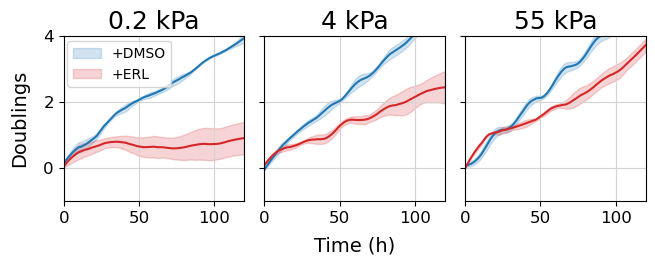

In [27]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = -1
ymax = 4

params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

t = np.arange(0,121)
axes[0].plot(t, savgol_filter(means[0],win,pol), color=c1)
axes[0].fill_between(t, savgol_filter(means[0] - stdevs[0],win,pol),
                     savgol_filter(means[0] + stdevs[0],win,pol), color=c1, alpha=0.2, label='+DMSO')
axes[0].plot(t, savgol_filter(means[1],win,pol), color=c2)
axes[0].fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c2, alpha=0.2, label='+ERL')
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('0.2 kPa')
axes[0].grid(color='lightgray')
axes[0].legend(loc=(0.02,0.69))

axes[1].plot(t, savgol_filter(means[2],win,pol), color=c1)
axes[1].fill_between(t, savgol_filter(means[2] - stdevs[2],win,pol), 
                     savgol_filter(means[2] + stdevs[2],win,pol), color=c1, alpha=0.2)
axes[1].plot(t, savgol_filter(means[3],win,pol), color=c2)
axes[1].fill_between(t, savgol_filter(means[3] - stdevs[3],win,pol), 
                     savgol_filter(means[3] + stdevs[3],win,pol), color=c2, alpha=0.2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].title.set_text('4 kPa')
axes[1].grid(color='lightgray')

axes[2].plot(t, savgol_filter(means[4],win,pol), color=c1)
axes[2].fill_between(t, savgol_filter(means[4] - stdevs[4],win,pol), 
                     savgol_filter(means[4] + stdevs[4],win,pol), color=c1, alpha=0.2)
axes[2].plot(t, savgol_filter(means[5],win,pol), color=c2)
axes[2].fill_between(t, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].title.set_text('55 kPa')
axes[2].grid(color='lightgray')


    
ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Doublings', labelpad=25)
fig.tight_layout(rect=(0, 0, 1, 1))

fig3a_fn = Path(SAVEDIR, 'fig3a.svg')

if SAVEFILES and (OVERWRITE or not fig3a_fn.exists()):
    plt.savefig(fig3a_fn, bbox_inches='tight')
else:
    plt.figure()

In [28]:
IMT_DATADIR = Path("C:\\Users\\olesk\\ECM_mod_output")

In [29]:
file_location = os.path.join(IMT_DATADIR,'*IMTs*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames

['C:\\Users\\olesk\\ECM_mod_output\\IMTs_0.6 kPa DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\IMTs_0.6 kPa erlotinib_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\IMTs_4 kPa DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\IMTs_4 kPa erlotinib_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\IMTs_55 kPa DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\IMTs_55 kPa erlotinib_param_orig.csv']

In [30]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

# ii=0
# for df in IMTs:
#     df["IMT"] = df["Division"] - df["Mitotic Frame"]
#     df["G1"] = df["Green On"] - df["Mitotic Frame"]
#     df["S-M"] = df["Division"] - df["Green On"]
#     if ii == 2 or ii == 3 or ii == 6 or ii == 7:
#         df["IMT_t"] = df["IMT"] * (32/60)
#         df["G1_t"] = df["G1"] * (32/60)
#         df["S-M_t"] = df["S-M"] * (32/60)
#     else:
#         df["IMT_t"] = df["IMT"] * (20/60)
#         df["G1_t"] = df["G1"] * (20/60)
#         df["S-M_t"] = df["S-M"] * (20/60)
#     #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
#     ii+=1
    
# stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
# ii=0
# for df in IMTs:
#     tmp_stiff = np.ones(len(df))*stiffs[ii]
#     df.insert(0, "Stiffness", tmp_stiff)
#     if ii % 2 == 0:
#         df["Drug"] = "DMSO"
#     else:
#         df["Drug"] = "ERL"    
#     ii+=1

# all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 


In [31]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian

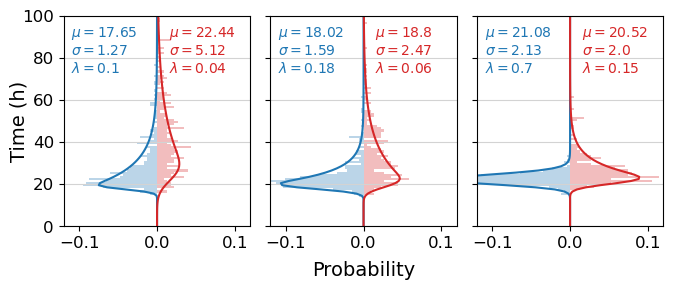

In [32]:
win = 21
pol = 2
size = (7.25,3.25)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

data = np.array(IMTs[0])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)


data = np.array(IMTs[1])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[2])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[3])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[4])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[5])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)



ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))

fig3b_fn = Path(SAVEDIR, 'fig3b.svg')

if SAVEFILES and (OVERWRITE or not fig1b_fn.exists()):
    plt.savefig(fig3b_fn, bbox_inches='tight')
else:
    plt.figure()

In [33]:
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
from scipy import stats
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.special import rel_entr
from sklearn.neighbors import KernelDensity
import scipy.optimize as opt

In [34]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic

In [35]:
from math import log10, floor
def round_sig(x, sig=2):
    return round(x, sig-int(floor(log10(abs(x))))-1)

def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-9
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

# def logl_emg2v2(log_par, data):
#     l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
#     eps = 10e-12
#     return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

def logl_emg2v2(log_par, data):
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-12
    temg2 = list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w))
    emg2 = [x + eps for x in temg2]
    return np.log(emg2).sum()

def calc_aicc(AIC, num_params, samp_size):
    aicc = AIC + (2*num_params*(num_params+1)/(samp_size-num_params-1))
    return aicc

def calc_aicp(AICs):
    aicp = [math.exp((min(AICs)-AIC)/2) for AIC in AICs]
    return aicp


def emg_mle_v2(data, log_par, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def emg2_mle_v2(data, log_par2, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params



In [36]:
init = [[-2.952, 0.369, 2.329, -2.253, 2.444, 3.315, -0.548], 
       [-2.81, 0.67, 2.32, -2.60, 2.1, 3.33, -0.50],
       [-2.81, 0.67, 2.32, -2.60, 2.1, 3.33, -0.50]]

In [37]:
init = [[0.11899839,  4.        , 13.94547197,  0.08924689, 15.2675382 ,
       37.47596956,  0.27418038], 
       [4.62241956e-01, 4.67312652e+00, 1.28838124e+01, 1.31917438e-01,
       1.50961259e-03, 2.45004542e+01, 7.16776171e-01],
       [1.06154452e-01, 2.34817118e+00, 9.59539352e+00, 1.36585838e-01,
       1.66645146e-03, 3.44994999e+01, 9.49848384e-01]]

In [38]:
file_location = os.path.join(IMT_DATADIR,'*g1_erl*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames

[]

In [19]:
g1 = []
for f in filenames:
    tmp_df = pd.read_csv(f,header=None).transpose()
#     tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    g1.append(tmp_df)

In [20]:
import warnings

In [84]:
def fit_EMGMM(G1_times, initial=init[0], ax=None, loc=4):
#     G1_times = dat[(dat['Stiffness']==cond['stiff']) & (dat['Drug']==cond['drug'])]['G1_t']
#     G1_times = G1_times[~np.isnan(G1_times)]
    
    params = exponnorm.fit(G1_times)
    exp_c = 1/(params[0]*params[2])
    LL = exponnorm.logpdf(G1_times,*params).sum()
    AIC = calculate_aic(LL, 3)
    AICc = calc_aicc(AIC, 3, len(G1_times))
    
    bounds = ((-4, 5),
             (-4, 8),
             (-4, 8),
             (-4, 5),
             (-4, 8),
             (-4, 8),
             (-4, -0.001))

    [log_p2, params2] = emg2_mle_v2(G1_times, initial, bounds)

    x = np.arange(0,100,0.1)
    y = emg_fit_func_2(x,*params2)
    y1 = emg_fit_func(x, params2[0], params2[1], params2[2])*params2[6]
    y2 = emg_fit_func(x, params2[3], params2[4], params2[5])*(1-params2[6])
    y3 = exponnorm.pdf(x, *params)
    ax.plot(x,y, color='black')
    ax.plot(x,y1, color='black', linestyle='dashed')
    ax.plot(x,y2, color='black', linestyle='dashed')
    ax.plot(x,y3, color='gray')
    h, edges =np.histogram(G1_times, bins=range(0,101), density=True)
    ax.stairs(h, edges, fill=True, color="tab:red", alpha=0.2)

    LL2 = logl_emg2v2(log_p2, G1_times)
    AIC2 = calculate_aic(LL2, 7)
    AICc2 = calc_aicc(AIC2, 7, len(G1_times))
    
    AICs = [AICc, AICc2]
    AICp = calc_aicp(AICs)
    AICp_r = [round_sig(AICp[0], 3), round_sig(AICp[1], 3)]
    
    rc('text', usetex=True)
    ax.text(loc, 0.11, r'$\underline{AICp}$', fontsize=12)
    rc('text', usetex=False)
    ax.text(loc, 0.097, f'EMG: {AICp_r[0]}', fontsize=12, color='gray')
    ax.text(loc, 0.087, f'EMG2: {AICp_r[1]}', fontsize=12)

    out = pd.Series(data={'LL':LL, 'AIC':AIC, 'AICc':AICc, 'params':params,
                         'LL2':LL2, 'AIC2':AIC2, 'AICc2':AICc2, 'params2':params2, 'AICp':AICp})
          
    return(out)
    

In [220]:
def smooth(y, box_pts):
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    return y_smooth

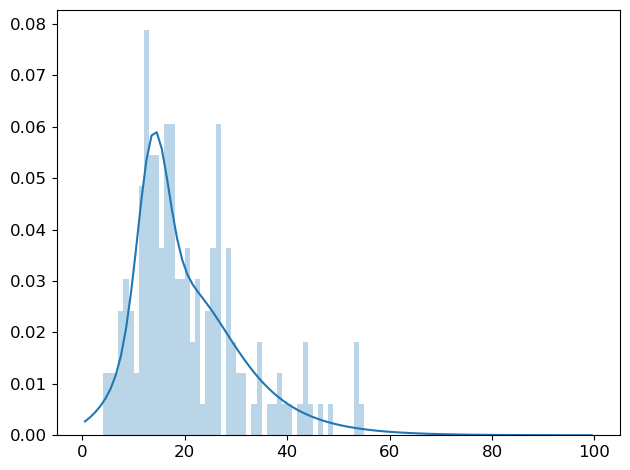

In [249]:
emg_init = [0.07, 4, 15, 0.07, 2, 40, 0.5]
emg_bounds = [[0, 0, 0, 0, 0, 0, 0], [10, 20, 30, 10, 100, 100, 1]]
h, edges =np.histogram(g1[1], bins=range(0,101), density=True)
tmp = smooth(h,7)
out = plt.stairs(h, edges, fill=True, color=c1, alpha=0.3)
popt2,pcov2=(curve_fit(emg_fit_func_2, centers, h, p0=emg_init, bounds=emg_bounds, maxfev=5000))
fitted_curve=list(emg_fit_func_2(centers,*popt2))
plt.plot(centers, fitted_curve, color=c1)
log_par2 = [math.log(x) for x in popt2 ]

In [103]:
popt2

array([1.06135683e-01, 2.34710215e+00, 9.59502189e+00, 1.36603846e-01,
       1.40309586e-03, 3.44995792e+01, 9.49867702e-01])

In [97]:
bounds = ((-2, 5),
         (-2, 5),
         (-4, 5),
         (-4, 5),
         (-4, 5),
         (-4, 5),
         (-4, -0.01))

[log_p2, params2] = emg2_mle_v2(g1[1], popt2, bounds)

In [99]:
params2

[1.1119727426018273,
 10.455228101832848,
 148.4131591025766,
 1.1463739182254549,
 1.0014040806563347,
 148.4131591025766,
 0.9900498337491681]

In [253]:
def fit_EMGMM2(G1_times, initial=init[0], ax=None, loc=4):
#     G1_times = dat[(dat['Stiffness']==cond['stiff']) & (dat['Drug']==cond['drug'])]['G1_t']
#     G1_times = G1_times[~np.isnan(G1_times)]
    
    params = exponnorm.fit(G1_times)
    exp_c = 1/(params[0]*params[2])
    LL = exponnorm.logpdf(G1_times,*params).sum()
    AIC = calculate_aic(LL, 3)
    AICc = calc_aicc(AIC, 3, len(G1_times))

    emg_init = [0.07, 4, 15, 0.07, 2, 40, 0.5]
    emg_bounds = [[0, 2, 0, 0, 2, 20, 0], [10, 20, 30, 10, 100, 100, 1]]
    h, edges =np.histogram(G1_times, bins=range(0,101), density=True)
    h = smooth(h,7)
    popt2,pcov2=(curve_fit(emg_fit_func_2, centers, h, p0=emg_init, bounds=emg_bounds, maxfev=5000))
    fitted_curve=list(emg_fit_func_2(centers,*popt2))
    log_par2 = [math.log(x) for x in popt2 ]

    x = np.arange(0,100,0.1)
    y = emg_fit_func_2(x,*popt2)
    y1 = emg_fit_func(x, popt2[0], popt2[1], popt2[2])*popt2[6]
    y2 = emg_fit_func(x, popt2[3], popt2[4], popt2[5])*(1-popt2[6])
    y3 = exponnorm.pdf(x, *params)
    ax.plot(x,y, color='black')
    ax.plot(x,y1, color='black', linestyle='dashed')
    ax.plot(x,y2, color='black', linestyle='dashed')
    ax.plot(x,y3, color='gray')
    h, edges =np.histogram(G1_times, bins=range(0,101), density=True)
    ax.stairs(h, edges, fill=True, color="tab:red", alpha=0.2)

    LL2 = logl_emg2v2(log_par2, G1_times)
    AIC2 = calculate_aic(LL2, 7)
    AICc2 = calc_aicc(AIC2, 7, len(G1_times))
    
    AICs = [AICc, AICc2]
    AICp = calc_aicp(AICs)
    AICp_r = [round_sig(AICp[0], 3), round_sig(AICp[1], 3)]
    
    rc('text', usetex=True)
    ax.text(loc, 0.11, r'$\underline{AICp}$', fontsize=12)
    rc('text', usetex=False)
    ax.text(loc, 0.097, f'EMG: {AICp_r[0]}', fontsize=12, color='gray')
    ax.text(loc, 0.087, f'EMG2: {AICp_r[1]}', fontsize=12)

    out = pd.Series(data={'LL':LL, 'AIC':AIC, 'AICc':AICc, 'params':params,
                         'LL2':LL2, 'AIC2':AIC2, 'AICc2':AICc2, 'params2':popt2, 'AICp':AICp})
          
    return(out)
    

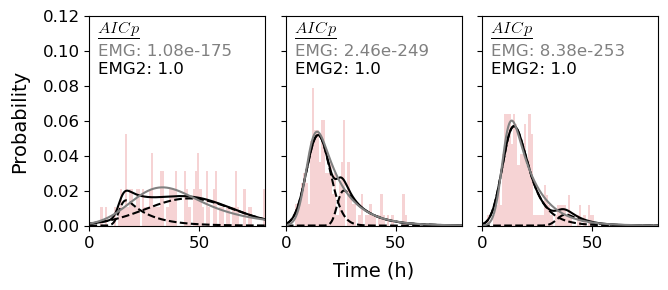

In [254]:
win = 21
pol = 2
size = (7.25,3.25)
ymin = 0
ymax = 0.12
xmin = 0
xmax = 80

#warnings.filterwarnings('ignore')
# rc('text', usetex=True)
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

f0 = fit_EMGMM2(g1[0], initial=init[0], ax=axes[0])
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
f1 = fit_EMGMM2(g1[1], initial=init[1], ax=axes[1])
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
f2 = fit_EMGMM2(g1[2], initial=init[2], ax=axes[2])
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])

ax1 = fig.add_subplot(111, frameon=False)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlabel('Time (h)', labelpad=22)
ax1.set_ylabel('Probability', labelpad=40)
fig.tight_layout(rect=(0, 0, 1, 1))

fig3c_fn = Path(SAVEDIR, 'fig3c.svg')

if SAVEFILES and (OVERWRITE or not fig3c_fn.exists()):
    plt.savefig(fig3c_fn, bbox_inches='tight')
else:
    plt.figure()

In [263]:
f0

LL                                               -432.707311
AIC                                               871.414621
AICc                                              871.672686
params     (1.7428673651750777, 22.14690327419673, 11.602...
LL2                                               -25.328436
AIC2                                               64.656872
AICc2                                              65.915299
params2    [0.0919524668222732, 2.00000000000001, 13.6438...
AICp                          [1.0764816706611905e-175, 1.0]
dtype: object

In [266]:
log_par2 = [math.log(x) for x in f0.params2 ]  
log_par2

[-2.3864835004257277,
 0.6931471805599504,
 2.613292104595213,
 -1.612092472321425,
 2.962164141578774,
 3.701918594324154,
 -1.494831593163848]

In [ ]:
LL2 = logl_emg2v2(log_par2, g1[2])
LL2

In [245]:
emg_init = [0.05, 4, 20, 0.05, 4, 30, 0.5]
emg_bounds = [[0, 0, 0, 0, 0, 0, 0], [0.9, 20, 30, 0.9, 100, 100, 1]]
h, edges =np.histogram(data, bins=range(0,101), density=True)
popt2,pcov2=(curve_fit(emg_fit_func_2, centers, h, p0=emg_init, bounds=emg_bounds, maxfev=5000))
fitted_curve=list(emg_fit_func_2(centers,*popt2))
log_par2 = [math.log(x) for x in popt2 ]

In [246]:
log_par2

[-0.7336086777525216,
 1.549375442214903,
 2.560891530349582,
 -2.0159108722559935,
 -0.7651045034023237,
 3.204036213082291,
 -0.33010539195688815]

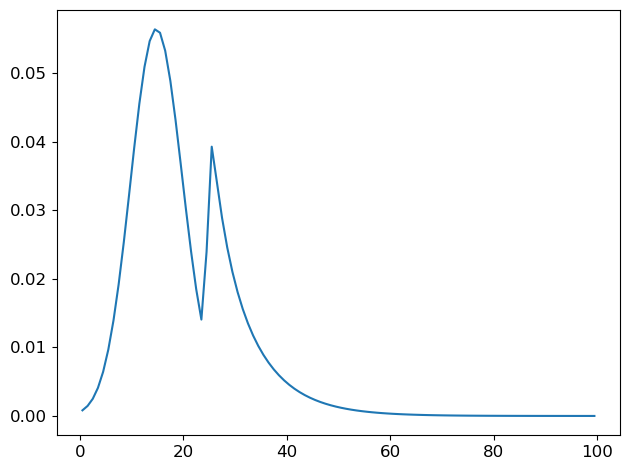

In [247]:
plt.plot(centers, fitted_curve)

In [89]:
data = g1[1]

In [90]:
init = [[-2.952, 0.369, 2.329, -2.253, 2.444, 3.315, -0.548], 
       [-2.145, 0.894, 2.314, -2.709, 1.079, 3.412, -0.105],
       [-0.452, 0.396, 2.388, -1.480, 1.021, 2.768, -0.010]]

In [91]:
log_par2 = [-0.733854099352687,
 1.5493495634418828,
 2.5608607558451637,
 -2.0159380846617765,
 -0.7654298091153476,
 3.2040355330684225,
 -0.3300993426767814]

log_par2 = [-0.733854099352687,
 1.5493495634418828,
 2.5608607558451637,
 -2.0159380846617765,
 -0.7654298091153476,
 5,
 -0.3]

In [92]:
bounds = ((-5, 5),
         (-5, 8),
         (-5, 8),
         (-5, 5),
         (-5, 8),
         (-5, 8),
         (-10, -0.00000001))

[log_p2, params2] = emg2_mle_v2(data, log_par2, bounds)

In [93]:
log_p2

array([-0.7338541 ,  1.54934956,  2.56086076, -2.01593808, -0.76542981,
        5.        , -0.3       ])